<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
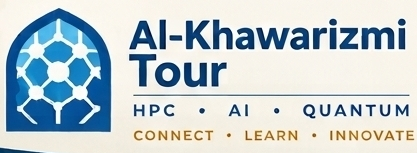
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · WEEK-2 TEAM CHALLENGE NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">The Cholesky Speed Run — from nested loops to vendor speed, in Julia</h1>
<p style="color:#e6eef8;margin:0;">Chapter 0: a working baseline (SPD system · element-wise nested-loop solver · backward error) · Chapters 1–8: the week-long <b>Cholesky Speed Run</b> — parallelism, task granularity, precision, data movement, BLAS/LAPACK, benchmarking and the roofline model</p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Hatem Ltaief</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **Chapter 0 · The baseline** (P1–P5) | during the webinar | complete, working reference code: SPD system, element-wise nested-loop Cholesky solver, backward-error validation |
| **Chapters 1–8 · Team challenge** | the whole week | fill in the `# TODO` cells, run the experiments, answer in `ANSWERS`, complete the performance report card |

**Kernel.** This is a **Julia** notebook (Julia ≥ 1.9 with IJulia). If Jupyter opens it with a Python kernel, `using …` fails with `SyntaxError: invalid syntax` → *Kernel → Change Kernel → Julia*.
**Threads.** Julia's thread count is fixed when the kernel starts. Create a multi-threaded kernel once, then select it:
`using IJulia; installkernel("Julia (8 threads)", env = Dict("JULIA_NUM_THREADS" => "8"))`
**Packages.** Only Julia standard libraries are required. `Plots.jl` is optional (without it, plotting helpers print tables): `using Pkg; Pkg.add("Plots")`.
**Speed.** `QUICK = true` (or environment variable `CHOL_QUICK=1`) uses small sizes while you develop. Final results: `QUICK = false`.

### Rules for automated grading
1. **Do not rename** the functions, keyword arguments and variables of the grading contract below. The grader calls your functions on **its own matrices** (other seeds and sizes, `N` not a multiple of your tile size), so they must work for any `N` and element type.
2. Every factorization works **in place** on the lower triangle and **returns the matrix** (`return A`). Solve with the provided `chol_solve!`.
3. Write code only in cells tagged `# TODO`. Cells tagged `# PROVIDED` and `# CHECK` are locked — do not change them.
4. Written answers go into `ANSWERS["…"]` (strings, 2–4 sentences); numbers into `record!("key", value)`. Everything is exported to `results_team<ID>.json` by the last cell.
5. The notebook must pass **Kernel → Restart & Run All** without errors. An unfinished task only shows ❌ in its `CHECK` cell, and an unfinished implementation is skipped (with a warning) in the Chapter 6 sweep.
6. **How you are graded.** The instructor re-runs your notebook from scratch and then runs additional *hidden* tests: your functions are called on other matrices (other seeds, sizes and element types). Your `CHECK` cells are a preview, not the grade. Written parts are graded with a rubric: numbers must come from your own runs and match the exported JSON.
7. **Runtime.** With `QUICK = false`, a complete run (mostly the Chapter 6 sweep up to N = 4096) can take from 10 to 40 minutes on a laptop. Develop with `QUICK = true` and do one final full run.

### Grading contract
| Chapter | Must exist (exact names) | Recorded |
|---|---|---|
| 0 | `generate_spd`, `generate_solution`, `matvec_naive`, `cholesky_naive!`, `chol_solve!`, `backward_error` *(provided)* | `P_*` |
| 1 | `cholesky_threads!(A; ntasks)` | `T1_times`, `T1_speedup_max`, `T1_serial_fraction` |
| 2 | `tile_potrf!`, `tile_trsm!`, `tile_update!`, `cholesky_tiled!(A, nb; parallel)`, `BEST_NB` | `T2_nb_times`, `T2_best_nb`, `T2_tasks_per_nb` |
| 3 | `solve_mixed_ir(A, b; maxiter, tol, factor!)` → `(x, iters, history)` | `T3_times`, `T3_backward_errors`, `T3_ir_iters` |
| 4 | `cholesky_left!(A)` | `T4_times`, `T4_allocations` |
| 5 | `cholesky_lapack!(A)`, `cholesky_tiled_blas!(A, nb; parallel)` | `T5_times` |
| 6 | `BENCH` (rows from `measure`), `IMPLS` | `T6_slope`, `T6_best` |
| 7 | `stream_triad_bw()`, `PEAK_BW`, `PEAK_GFLOPS`, `PEAK_GFLOPS_THEORY`, `ARITH_INTENSITY`, `BOUND` | `T7_*` |
| 8 | report card + `ANSWERS["T8_*"]` | — |

The provided helpers `measure`, `safe_measure!`, `validate`, `bench` and `allocations` produce data in the format the grader reads; use them.

### Points
| # | Chapter | Points | auto-checked | read by instructor |
|---|---|---|---|---|
| 1 | Sequential vs parallel | 12 | 6 | 6 |
| 2 | Coarse vs fine-grained tasks | 14 | 6 | 8 |
| 3 | Precision | 14 | 6 | 8 |
| 4 | Data movement | 12 | 6 | 6 |
| 5 | Vendor libraries (BLAS / LAPACK) | 10 | 6 | 4 |
| 6 | Benchmarking: time & GFlop/s vs N | 12 | 6 | 6 |
| 7 | Roofline model | 14 | 5 | 9 |
| 8 | Report card & conclusions | 12 | 1 | 11 |
| ★ | HPC bonus | +10 | — | +10 |
| | **Total** | **100** | **42** | **58** |

**Suggested plan:** Day 1 Chapters 0–1 · Day 2 Chapter 2 · Day 3 Chapters 3–4 · Day 4 Chapter 5 · Days 5–6 Chapters 6–7 · Day 7 Chapter 8 (+ bonus).

### Webinar toolbox → where you use it
| Technique from the webinar | Chapter | Julia tools |
|---|---|---|
| Sequential vs parallel, speed-up, Amdahl's law | 1 | `Threads.@spawn`, `@sync`, `nthreads()` |
| Fine- vs coarse-grained tasks, tiling | 2 | tiles, `view`, one task per tile operation |
| Precision (FP64 / FP32 / FP16), mixed precision | 3 | generic element type `T`, iterative refinement |
| Reducing data movement | 4 | column-major loop order, `@inbounds`, `@simd`, `@allocated`, cache-sized tiles |
| Vendor-optimized libraries | 5 | `LinearAlgebra.BLAS`, `LinearAlgebra.LAPACK`, `BLAS.set_num_threads` |
| Benchmarking methodology | 6 | warm-up, minimum of repetitions, Time and GFlop/s vs N |
| Roofline performance model | 7 | STREAM triad, GEMM peak, arithmetic intensity |

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The agency's virtual PM2.5 sensor is being upgraded to a <b>Gaussian-process (kriging)</b> estimator. Every hour it builds a covariance matrix <b>K</b> over stations and recent hours and solves <b>K α = y</b>. K is dense, <b>symmetric positive definite</b>, and its size N grows into the thousands. The prototype, written by an intern over a weekend, is three nested loops: correct, and far too slow to run every hour.<br>
Your squad has one week to make it fast <b>without ever breaking correctness</b>: every speed-up must pass the backward-error test. Each chapter adds one technique from the webinar, and each one ends with a <i>plot twist</i> that leads to the next.<br>
<b>Deliver:</b> working, validated implementations · speed-up, granularity, precision and data-movement studies · a benchmark of Time and GFlop/s against N · a roofline analysis · a one-page <b>performance report card</b> with your recommendation.</div>

---
# Chapter 0 · The baseline — *Monday, 9:00: the intern's code*
## 0 · Setup

In [79]:
# PROVIDED · 0.1 Parameters and environment (you may edit TEAM_ID and QUICK)
TEAM_ID = 1013                                      # ← your team number
SEED    = 2000 + TEAM_ID
QUICK   = get(ENV, "CHOL_QUICK", "0") == "1"      # true → small sizes (development / autograder)
QUICK = true                                    # ← uncomment while developing, comment out for final results

N           = QUICK ? 256 : 1024                  # problem size for single experiments (parametrized)
SIZES       = QUICK ? [128, 256, 384] : [256, 512, 1024, 2048, 4096]   # benchmark sweep (Chapter 6)
NAIVE_MAX_N = QUICK ? 384 : 1024                  # the baseline is slow: it is never run above this size
REPS        = QUICK ? 1 : 3                       # timing repetitions (the minimum is reported)

using LinearAlgebra, Random, Printf, Statistics, Dates
using Base.Threads

VERSION < v"1.9" && @warn "This notebook needs Julia ≥ 1.9 (you have $VERSION)."
BLAS_THREADS0 = BLAS.get_num_threads()            # remembered so Chapter 5 can restore it
println("Julia ", VERSION, " | Julia threads: ", nthreads(), " | BLAS threads: ", BLAS_THREADS0)
println("BLAS/LAPACK: ", BLAS.get_config())
println("CPU: ", Sys.cpu_info()[1].model, " | logical cores: ", Sys.CPU_THREADS)
println("N = $N | sizes = $SIZES | QUICK = $QUICK")
nthreads() == 1 && @warn "Julia runs with 1 thread: Chapters 1–2 need more. Create a threaded kernel: using IJulia; installkernel(\"Julia (8 threads)\", env = Dict(\"JULIA_NUM_THREADS\" => \"8\"))"

const HAS_PLOTS = Base.find_package("Plots") !== nothing
if HAS_PLOTS
    using Plots
else
    @info "Plots.jl not found → plotting helpers print tables instead. Install with: using Pkg; Pkg.add(\"Plots\")"
end

Julia 1.13.2 | Julia threads: 12 | BLAS threads: 6
BLAS/LAPACK: LBTConfig([ILP64] libopenblas64_.dll)
CPU: 13th Gen Intel(R) Core(TM) i7-1355U | logical cores: 12
N = 256 | sizes = [128, 256, 384] | QUICK = true


In [80]:
# PROVIDED · 0.2 Helpers used by every chapter — do not edit
RESULTS  = Dict{String,Any}()        # numbers you record!       → exported for grading
ANSWERS  = Dict{String,String}()     # your short written answers → exported for grading
CHECKS   = Dict{String,Any}()        # outcome of every CHECK cell
BENCH    = NamedTuple[]              # Chapter 6 benchmark rows (built with `measure`)
record!(key::AbstractString, value) = (RESULTS[key] = value; value)

"Run a self-check. Never throws, so Restart & Run All always reaches the end."
function check(name::AbstractString, test::Function; points::Real = 0)
    ok = try
        test() === true
    catch err
        println("   ↳ ", first(sprint(showerror, err), 300))
        false
    end
    CHECKS[name] = Dict("pass" => ok, "points" => points)
    println(ok ? "✅ " : "❌ ", name, points > 0 ? "  [$(points) pt]" : "")
    return ok
end

# ---------- performance metrics ----------
chol_flops(n) = n^3 / 3 + n^2 / 2 + n / 6       # exact flop count of a Cholesky factorization (≈ n³/3)
gflops(flops, t) = flops / t / 1e9

"""
    bench(f!, A; reps = REPS) -> seconds
Time the in-place factorization `f!` on fresh copies of `A`: a small warm-up call (JIT compilation),
then the minimum over `reps` runs. Copying is done outside the timed region.
"""
function bench(f!, A::AbstractMatrix; reps::Int = REPS)
    m = min(size(A, 1), 64)
    f!(A[1:m, 1:m])                      # warm-up: compiles f! for this element type
    B = similar(A)
    best = Inf
    for _ in 1:reps
        copyto!(B, A)
        best = min(best, @elapsed f!(B))
    end
    return best
end

"Heap bytes allocated by one call f!(copy of A), measured after a warm-up."
function allocations(f!, A::AbstractMatrix)
    B = copy(A); f!(B)
    copyto!(B, A)
    return @allocated f!(B)
end

# ---------- accuracy metrics (always evaluated in Float64) ----------
"Normwise backward error η = ‖b − A x‖∞ / (‖A‖∞ ‖x‖∞ + ‖b‖∞) (Rigal–Gaches). Backward stable ⇔ η = O(ε)."
function backward_error(A, x, b)
    A64, x64, b64 = Float64.(A), Float64.(x), Float64.(b)
    r = b64 - A64 * x64
    return norm(r, Inf) / (opnorm(A64, Inf) * norm(x64, Inf) + norm(b64, Inf))
end

"Relative forward error ‖x − x_true‖∞ / ‖x_true‖∞ (rule of thumb: ≲ κ(A)·η)."
forward_error(x, x_true) = norm(Float64.(x) .- Float64.(x_true), Inf) / norm(Float64.(x_true), Inf)

"Factorization backward error ‖A − L Lᵀ‖₁ / ‖A‖₁ (uses only the lower triangle of F)."
function factorization_error(A, F)
    L = LowerTriangular(Float64.(F))
    A64 = Float64.(A)
    return opnorm(A64 - L * L', 1) / opnorm(A64, 1)
end

"""
    validate(f!; n = 203, T = Float64, seed = 7) -> backward error
Exactly what the grader does: factor a *fresh* SPD matrix (n is not a multiple of any tile size) with `f!`,
solve with `chol_solve!`, return the backward error. `f!` must return the factored matrix.
"""
function validate(f!; n::Int = 203, T::Type{<:AbstractFloat} = Float64, seed::Int = 7)
    A = generate_spd(n; T = T, seed = seed)
    b = A * generate_solution(n; T = T, seed = seed + 1)
    F = f!(copy(A))
    F isa AbstractMatrix || error("the factorization must return the factored matrix (got $(typeof(F)))")
    return backward_error(A, chol_solve!(F, copy(b)), b)
end
passes(f!; n::Int = 203, T::Type{<:AbstractFloat} = Float64, tol::Real = 10 * n * eps(T)) =
    validate(f!; n = n, T = T) <= tol

"""
    measure(name, f!, A, b; reps = REPS) -> NamedTuple
One benchmark row in the schema the grader expects. Times the factorization only (flops = n³/3)
and validates the solve with the backward error.
"""
function measure(name::AbstractString, f!, A::AbstractMatrix{T}, b::AbstractVector; reps::Int = REPS) where {T}
    n = size(A, 1)
    t = bench(f!, A; reps = reps)
    F = f!(copy(A))
    x = chol_solve!(F, T.(b))
    return (impl = String(name), precision = string(T), N = n, threads = nthreads(),
            time_s = t, gflops = gflops(chol_flops(n), t), backward_error = backward_error(A, x, b))
end

"Like push!(rows, measure(...)), but an unfinished or failing implementation is skipped with a warning instead of stopping the run."
function safe_measure!(rows, name, f!, A, b; kw...)
    try
        push!(rows, measure(name, f!, A, b; kw...))
    catch err
        @warn "skipped $(name) (N = $(size(A, 1)), $(eltype(A))): $(first(sprint(showerror, err), 120))"
    end
    return rows
end

"Print a vector of NamedTuples as an aligned table."
function show_table(rows; w::Int = 15)
    isempty(rows) && return println("(no rows)")
    fmt(v) = v isa AbstractFloat ? @sprintf("%.4g", v) : string(v)
    println(join([rpad(string(k), w) for k in keys(first(rows))]))
    for r in rows
        println(join([rpad(fmt(v), w) for v in values(r)]))
    end
end

# ---------- minimal JSON writer (no package needed) ----------
_esc(s::AbstractString) = replace(s, "\\" => "\\\\", "\"" => "\\\"", "\n" => "\\n", "\r" => "\\r", "\t" => "\\t")
to_json(x::Nothing) = "null"
to_json(x::Bool) = x ? "true" : "false"
to_json(x::Integer) = string(x)
to_json(x::AbstractFloat) = isfinite(x) ? string(Float64(x)) : "null"
to_json(x::Union{AbstractString,Symbol}) = "\"" * _esc(string(x)) * "\""
to_json(x::AbstractDict) = "{" * join([to_json(string(k)) * ":" * to_json(v) for (k, v) in x], ",") * "}"
to_json(x::NamedTuple) = to_json(Dict(string(k) => v for (k, v) in pairs(x)))
to_json(x::Union{AbstractVector,Tuple}) = "[" * join([to_json(v) for v in x], ",") * "]"
to_json(x) = to_json(string(x))
println("helpers loaded")

helpers loaded


<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 0 — Monday, 9:00: the intern's code</b><br>The squad opens the prototype. It builds a test system whose answer is known in advance, solves it with three nested loops, and checks the result. Before optimizing anything, you run it once, understand it, and write down how slow it is. That number is the <b>baseline</b> every later chapter is measured against.</div>

## P1 · A random dense symmetric positive definite matrix of size N
For a random $M$, the matrix $MM^\top$ is symmetric positive semi-definite. Adding $N\cdot I$ shifts every eigenvalue up by $N$, so $A = MM^\top + N I$ is strictly positive definite and well conditioned. Averaging with the transpose removes the round-off asymmetry of the product.

In [81]:
# PROVIDED · P1
function generate_spd(N::Integer; T::Type{<:AbstractFloat} = Float64, seed::Integer = SEED)
    rng = Xoshiro(seed)
    M = rand(rng, T, N, N)
    A = M * M' + T(N) * I            # MMᵀ ⪰ 0, + N·I ≻ 0
    return Matrix{T}((A + A') / 2)    # exact symmetry
end

A = generate_spd(N)
@printf("A: %d×%d %s | symmetric: %s | positive definite: %s\n", size(A, 1), size(A, 2), eltype(A), issymmetric(A), isposdef(A))

A: 256×256 Float64 | symmetric: true | positive definite: true


## P2 · An analytical solution vector of size N
Entries in $[1, 2)$, so no component is close to zero and relative errors are meaningful.

In [82]:
# PROVIDED · P2
generate_solution(N::Integer; T::Type{<:AbstractFloat} = Float64, seed::Integer = SEED + 1) =
    rand(Xoshiro(seed), T, N) .+ one(T)

x_true = generate_solution(N)
@printf("x_true: length %d, entries in [%.3f, %.3f]\n", length(x_true), minimum(x_true), maximum(x_true))

x_true: length 256, entries in [1.003, 1.993]


## P3 · Right-hand side $b = A\,x_{\text{true}}$ (element-wise loops)

In [83]:
# PROVIDED · P3
function matvec_naive(A::AbstractMatrix, x::AbstractVector)
    n, m = size(A)
    b = zeros(promote_type(eltype(A), eltype(x)), n)
    for i in 1:n
        s = zero(eltype(b))
        for j in 1:m
            s += A[i, j] * x[j]
        end
        b[i] = s
    end
    return b
end

b = matvec_naive(A, x_true)
@printf("‖b − A*x_true‖∞ / ‖b‖∞ = %.2e  (loops vs BLAS: only the summation order differs)\n",
        norm(b - A * x_true, Inf) / norm(b, Inf))

‖b − A*x_true‖∞ / ‖b‖∞ = 1.45e-15  (loops vs BLAS: only the summation order differs)


## P4 · Solve $A x = b$ with element-wise nested loops
**Cholesky–Banachiewicz** (row by row), in place: $L$ overwrites the lower triangle of $A$.

$$L_{ij} = \frac{1}{L_{jj}}\Big(A_{ij} - \sum_{k<j} L_{ik}L_{jk}\Big)\ (j<i), \qquad L_{ii} = \sqrt{A_{ii} - \sum_{k<i} L_{ik}^2}$$

Then forward substitution $Ly=b$ and backward substitution $L^\top x = y$. Cost: $n^3/3$ flops for the factorization, $2n^2$ for the two solves.

In [84]:
# PROVIDED · P4
"""
    cholesky_naive!(A) -> A
In-place Cholesky A = L·Lᵀ. L overwrites the lower triangle of A; the strict upper triangle is not touched.
"""
function cholesky_naive!(A::AbstractMatrix{T}) where {T<:AbstractFloat}
    n = size(A, 1)
    for i in 1:n                     # row of L
        for j in 1:i                 # column of L
            s = zero(T)
            for k in 1:j-1           # dot product of rows i and j of L  ← walks ALONG rows (stride n in memory)
                s += A[i, k] * A[j, k]
            end
            if i == j
                d = A[i, i] - s
                d > zero(T) || throw(PosDefException(i))
                A[i, i] = sqrt(d)
            else
                A[i, j] = (A[i, j] - s) / A[j, j]
            end
        end
    end
    return A
end

"""
    chol_solve!(F, x) -> x
Solve A x = b with the factor F (lower triangle = L): forward L y = b, then backward Lᵀ x = y.
In place: on entry x = b, on exit x = solution. Used by every chapter and by the grader.
"""
function chol_solve!(F::AbstractMatrix, x::AbstractVector)
    n = length(x)
    for i in 1:n                     # forward substitution  L y = b
        s = x[i]
        for k in 1:i-1
            s -= F[i, k] * x[k]
        end
        x[i] = s / F[i, i]
    end
    for i in n:-1:1                  # backward substitution Lᵀ x = y   (Lᵀ[i,k] = L[k,i])
        s = x[i]
        for k in i+1:n
            s -= F[k, i] * x[k]
        end
        x[i] = s / F[i, i]
    end
    return x
end

solve_naive(A, b) = chol_solve!(cholesky_naive!(copy(A)), copy(b))

F = cholesky_naive!(copy(A))         # the first call also compiles the function
x = chol_solve!(F, copy(b))
if N <= NAIVE_MAX_N
    t_fact  = bench(cholesky_naive!, A)
    t_solve = @elapsed chol_solve!(F, copy(b))
    @printf("N = %d | factorization %.3f s (%.2f GFlop/s) | two triangular solves %.4f s\n",
            N, t_fact, gflops(chol_flops(N), t_fact), t_solve)
    record!("P_naive_time_s", t_fact); record!("P_naive_gflops", gflops(chol_flops(N), t_fact))
end

N = 256 | factorization 0.002 s (2.64 GFlop/s) | two triangular solves 0.0001 s


2.6434285714285712

## P5 · Validate with the backward error
The **normwise backward error** of the computed $\hat x$

$$\eta(\hat x) = \frac{\|b - A\hat x\|_\infty}{\|A\|_\infty\,\|\hat x\|_\infty + \|b\|_\infty}$$

is the smallest relative perturbation of $A$ and $b$ for which $\hat x$ is an *exact* solution. Cholesky is backward stable, so $\eta$ should be a modest multiple of the unit round-off $\varepsilon$, whatever the conditioning. The **forward error** $\|\hat x - x_{\text{true}}\|/\|x_{\text{true}}\|$ is additionally amplified by the condition number: $\lesssim \kappa(A)\,\eta$.

**This is the acceptance test for every implementation in this notebook:** $\eta \le 10\,N\,\varepsilon$.

In [85]:
# PROVIDED · P5
η  = backward_error(A, x, b)
ηf = factorization_error(A, F)
fe = forward_error(x, x_true)
@printf("backward error   η = %.2e   (η/ε = %.1f, ε = %.2e)\n", η, η / eps(Float64), eps(Float64))
@printf("factorization    ‖A − LLᵀ‖₁/‖A‖₁ = %.2e\n", ηf)
@printf("forward error    ‖x − x_true‖∞/‖x_true‖∞ = %.2e\n", fe)
record!("P_backward_error", η); record!("P_forward_error", fe)

backward error   η = 2.82e-16   (η/ε = 1.3, ε = 2.22e-16)
factorization    ‖A − LLᵀ‖₁/‖A‖₁ = 2.13e-16
forward error    ‖x − x_true‖∞/‖x_true‖∞ = 5.96e-14


5.960302845719987e-14

In [86]:
# CHECK · Chapter 0 (not graded — confirms your environment works)
check("P1 A is symmetric positive definite", () -> issymmetric(A) && isposdef(A))
check("P3 matvec_naive matches BLAS", () -> norm(matvec_naive(A, x_true) - A * x_true, Inf) <= N * eps() * opnorm(A, Inf) * norm(x_true, Inf))
check("P4 naive Cholesky matches LAPACK", () -> norm(tril(F) - cholesky(Symmetric(A, :L)).L, Inf) <= 1e-8 * norm(tril(F), Inf))
check("P5 backward error ≤ 10·N·ε", () -> η <= 10 * N * eps(Float64))
check("P  grader-style test (fresh matrix, N = 203, Float64 and Float32)", () -> passes(cholesky_naive!) && passes(cholesky_naive!; T = Float32))

✅ P1 A is symmetric positive definite
✅ P3 matvec_naive matches BLAS
✅ P4 naive Cholesky matches LAPACK
✅ P5 backward error ≤ 10·N·ε
✅ P  grader-style test (fresh matrix, N = 203, Float64 and Float32)


true

> *Plot twist:* the solver is correct, but at the hourly size it takes far too long, and it uses a single core of a machine that has many. **The rest of the week is about making it fast without breaking P5.**

---
# Chapter 1 · Sequential vs parallel — *More hands on deck* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 1</b><br>Your laptop has several cores and the baseline uses one. But the baseline cannot simply be split up: row <i>i</i> of L needs all previous rows. Rewrite the algorithm in its <b>right-looking</b> form, where after each column the whole trailing matrix is updated. Those updates are independent of one another, so that is where the threads go.</div>

### Task 1.1 · Implement `cholesky_threads!(A; ntasks)`
* Right-looking algorithm. For $j = 1{:}n$: (1) $A_{jj} \leftarrow \sqrt{A_{jj}}$, throwing `PosDefException(j)` if $A_{jj} \le 0$; (2) scale the column $A_{j+1:n,\,j} \mathrel{/}= A_{jj}$; (3) trailing update $A_{ik} \mathrel{-}= A_{ij}A_{kj}$ for $k = j{+}1{:}n$ and $i = k{:}n$.
* Parallelize step 3 over the columns $k$: split them into `ntasks` groups, `Threads.@spawn` one task per group, and wait for all of them inside `@sync` before moving to column $j+1$.
* `ntasks = 1` must give the purely sequential version (your reference $T_1$).
* *Load balance:* column $k$ costs $n-k+1$ updates, so contiguous blocks are unbalanced. Try a cyclic distribution, `k in j+t:ntasks:n` for `t = 1:ntasks`.

In [87]:
# TODO · Task 1.1
"""
    cholesky_threads!(A; ntasks = nthreads()) -> A
Right-looking in-place Cholesky with a threaded trailing update. L in the lower triangle of A.
"""
function cholesky_threads!(A::AbstractMatrix{T}; ntasks::Int = nthreads()) where {T<:AbstractFloat}
    error("TODO: Task 1.1 — implement cholesky_threads!")
    n = size(A, 1)
    for j in 1:n
        # 1. diagonal  2. scale column j  3. @sync over ntasks spawned tasks doing the trailing update
    end
    return A
end

cholesky_threads! (generic function with 1 method)

### Task 1.2 · Experiment: speed-up, efficiency, Amdahl
1. Time `cholesky_threads!` for `ntasks` $p \in \{1, 2, 4, \dots, \texttt{nthreads()}\}$ on `A` with `bench`.
2. Compute the speed-up $S_p = T_1/T_p$ and the efficiency $E_p = S_p/p$. Print a table and plot both against $p$. Add the baseline `cholesky_naive!` time for comparison.
3. Fit Amdahl's law $S_p = 1/\big(f + (1-f)/p\big)$ to estimate the serial fraction $f$.
4. `record!("T1_times", Dict(p => T_p))`, `record!("T1_speedup_max", …)`, `record!("T1_serial_fraction", f)`.

In [88]:
# TODO · Task 1.2
ps = unique(vcat([2^k for k in 0:floor(Int, log2(nthreads()))], nthreads()))   # 1, 2, 4, …, nthreads()
times = Dict{Int,Float64}()
# for p in ps
#     times[p] = bench(B -> cholesky_threads!(B; ntasks = p), A)
# end
# … speed-up / efficiency table and plot, Amdahl fit …
# record!("T1_times", times); record!("T1_speedup_max", …); record!("T1_serial_fraction", …)

Dict{Int64, Float64}()

In [89]:
# TODO · Task 1.3 — answers (2–4 sentences each)
ANSWERS["T1_scaling"]      = ""   # How does S_p behave as p grows, and why does it stop scaling? (Amdahl, one @sync per column, memory bandwidth)
ANSWERS["T1_dependencies"] = ""   # Why is the row-by-row baseline hard to parallelize while the right-looking trailing update is easy?

""

In [90]:
# CHECK · Chapter 1
check("T1 correct, sequential (ntasks = 1)", () -> passes(B -> cholesky_threads!(B; ntasks = 1)); points = 2)
check("T1 correct, parallel (ntasks = nthreads())", () -> passes(B -> cholesky_threads!(B; ntasks = nthreads())); points = 2)
check("T1 correct with more tasks than columns (n = 31, ntasks = 64)", () -> passes(B -> cholesky_threads!(B; ntasks = 64); n = 31); points = 1)
check("T1 timings and Amdahl fit recorded", () -> haskey(RESULTS, "T1_times") && length(RESULTS["T1_times"]) >= min(2, length(ps)) &&
                                                  haskey(RESULTS, "T1_serial_fraction"); points = 1)

   ↳ TODO: Task 1.1 — implement cholesky_threads!
❌ T1 correct, sequential (ntasks = 1)  [2 pt]
   ↳ TODO: Task 1.1 — implement cholesky_threads!
❌ T1 correct, parallel (ntasks = nthreads())  [2 pt]
   ↳ TODO: Task 1.1 — implement cholesky_threads!
❌ T1 correct with more tasks than columns (n = 31, ntasks = 64)  [1 pt]
❌ T1 timings and Amdahl fit recorded  [1 pt]


false

> *Plot twist:* for every one of the $n$ columns you spawn tasks and wait at a barrier, often for a few microseconds of work each. The tasks are too **fine-grained**. What if each task did a whole block of work instead?

---
# Chapter 2 · Coarse- vs fine-grained tasks — *The right size of a job* (14 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 2</b><br>Group the matrix into <b>tiles</b> of size nb × nb and make one task per <i>tile operation</i>. The tile size nb is now the knob that sets granularity. Small nb gives many tiny tasks, with high scheduling overhead and little cache reuse. Large nb gives a few big tasks, with idle threads and load imbalance. Somewhere in between is the sweet spot, and you have to find it.</div>

### Task 2.1 · Implement the tiled algorithm
With $p = \lceil n/nb \rceil$ tile rows, for $k = 1{:}p$:

| Step | Operation | Tiles | Parallel? |
|---|---|---|---|
| POTRF | $A_{kk} = L_{kk}L_{kk}^\top$ | diagonal tile $k$ | sequential |
| TRSM | $A_{ik} \leftarrow A_{ik}L_{kk}^{-\top}$ | $i = k{+}1{:}p$ | one task per tile |
| SYRK / GEMM | $A_{ij} \leftarrow A_{ij} - A_{ik}A_{jk}^\top$ | $k < j \le i \le p$ | one task per tile |

* Write the three tile kernels with **plain loops**. No BLAS here; that comes in Chapter 5.
* Use `view(A, tile(i, nb, n), tile(k, nb, n))` and never copies. The last tile may be smaller than nb, and nb may be larger than n.
* With `parallel = true`, wrap each phase in `@sync` and `Threads.@spawn` one task per tile. With `parallel = false`, run the same loops without tasks.

In [ ]:
# TODO · Task 2.1
tile(i::Int, nb::Int, n::Int) = ((i - 1) * nb + 1):min(i * nb, n)    # PROVIDED: rows/cols of tile i

"POTRF: factor a diagonal tile in place (lower triangle). Hint: any of your loop factorizations works on a view."
function tile_potrf!(Akk::AbstractMatrix)
    n = size(Akk, 1)

    for j in 1:n
        d = Akk[j, j]

        d > zero(eltype(Akk)) || throw(PosDefException(j))
        Akk[j, j] = sqrt(d)

        for i in j+1:n
            Akk[i, j] /= Akk[j, j]
        end

        for c in j+1:n
            for r in c:n
                Akk[r, c] -= Akk[r, j] * Akk[c, j]
            end
        end
    end
    
    return Akk
end

"TRSM: overwrite Aik with Aik · Lkk⁻ᵀ, i.e. solve X · Lkkᵀ = Aik row by row (forward substitution with Lkk)."
function tile_trsm!(Aik::AbstractMatrix, Lkk::AbstractMatrix)
    n = size(Aik, 1)
    m = size(Aik, 2)

    for i in 1:n
        for j in 1:m
            s = Aik[i, j]

            for t in 1:j-1
                s -= Aik[i, t] * Lkk[j, t]
            end
            
            Aik[i, j] = s / Lkk[j, j]
        end
    end

    return Aik
end

"SYRK/GEMM: Aij ← Aij − Aik · Ajkᵀ (on a diagonal tile only the lower triangle needs updating)."
function tile_update!(Aij::AbstractMatrix, Aik::AbstractMatrix, Ajk::AbstractMatrix)
    r = size(Aij, 1)
    c = size(Aij, 2)
    t = size(Aik, 2)

    for i in 1:r
        for j in 1:c
            s = zero(eltype(Aij))

            for k in 1:t
                s += Aik[i, k] * Ajk[j, k]
            end

            Aij[i, j] -= s
        end
    end

    return Aij
end

"""
    cholesky_tiled!(A, nb; parallel = true) -> A
Tiled right-looking Cholesky with one task per tile operation (see the table above).
"""
function cholesky_tiled!(A::AbstractMatrix{T}, nb::Int; parallel::Bool = true) where {T<:AbstractFloat}
    n = size(A, 1); p = cld(n, nb)
    for k in 1:p
        # POTRF → @sync TRSM tasks → @sync update tasks
        Akk = view(A, tile(k, nb, n), tile(k, nb, n))
        tile_potrf!(Akk)

        if parallel
            @sync begin
                for i in k+1:p
                    let Aik = view(A, tile(i, nb, n), tile(k, nb, n))
                        Lkk = Akk
                        Threads.@spawn tile_trsm!(Aik, Lkk)
                    end
                end
            end

            @sync begin
                for j in k+1:p
                    for i in j:p
                        let Aij = view(A, tile(i, nb, n), tile(j, nb, n)),
                            Aik = view(A, tile(i, nb, n), tile(k, nb, n)),
                            Ajk = view(A, tile(j, nb, n), tile(k, nb, n))
                            
                            Threads.@spawn tile_update!(Aij, Aik, Ajk)
                        end
                    end
                end
            end
        else 
            for i in k+1:p
                Aik = view(A, tile(i, nb, n), tile(k, nb, n))
                tile_trsm!(Aik, Akk)
            end

            for j in k+1:p
                for i in j:p
                    Aij = view(A, tile(i, nb, n), tile(j, nb, n))
                    Aik = view(A, tile(i, nb, n), tile(k, nb, n))
                    Ajk = view(A, tile(j, nb, n), tile(k, nb, n))

                    tile_update!(Aij, Aik, Ajk)
                end
            end
        end
    end

    return A
end

cholesky_tiled! (generic function with 1 method)

### Task 2.2 · Experiment: granularity sweep
1. Time `cholesky_tiled!(A, nb)` for nb in `NBS`, plus the sequential version (`parallel = false`) at your best nb.
2. For each nb, compute the **number of tasks** spawned and the **average flops per task**. Compare with Chapter 1, which has one barrier per column and $\approx n \cdot$`ntasks` spawns.
3. Plot time (or GFlop/s) against nb and explain the U-shape. Set `BEST_NB`; it is reused later.
4. `record!("T2_nb_times", Dict(nb => t))`, `record!("T2_best_nb", BEST_NB)`, `record!("T2_tasks_per_nb", Dict(nb => ntasks))`.

In [ ]:
# Parallel timing sweep

NBS = filter(nb -> nb <= N, [8, 16, 32, 64, 128, 256, 512])
nb_times = Dict{Int,Float64}()

for nb in NBS
    nb_times[nb] = bench(
        B -> cholesky_tiled!(B, nb; parallel = true),
        A
    )

    @printf("nb = %3d | time = %.3f ms\n", nb, 1000 * nb_times[nb])
end

nb =   8 | time = 2.435 ms
nb =  16 | time = 2.042 ms
nb =  32 | time = 2.833 ms
nb =  64 | time = 2.810 ms
nb = 128 | time = 3.535 ms
nb = 256 | time = 0.602 ms


#### Task counts and work per task

In [132]:
tasks_per_nb = Dict{Int,Int}()
avg_flops_per_task = Dict{Int,Float64}()

for nb in NBS
    p = cld(N, nb)
    count_tasks = 0
    total_flops = 0.0

    for k in 1:p
        q = length(tile(k, nb, N))

        # TRSM tasks
        for i in k+1:p
            ni = length(tile(i, nb, N))

            count_tasks += 1
            total_flops += ni * q^2
        end

        # UPDATE tasks
        for j in k+1:p
            nj = length(tile(j, nb, N))

            for i in j:p
                ni = length(tile(i, nb, N))

                count_tasks += 1
                total_flops += ni * nj * (2*q + 1)
            end
        end
    end

    tasks_per_nb[nb] = count_tasks
    avg_flops_per_task[nb] =
        count_tasks == 0 ? NaN : total_flops / count_tasks
end

#### Select `BEST_NB` and compare sequential versus parallel

In [135]:
BEST_NB = NBS[argmin([nb_times[nb] for nb in NBS])]

t_seq = bench(
    B -> cholesky_tiled!(B, BEST_NB; parallel = false),
    A
)

t_par = nb_times[BEST_NB]
speedup = t_seq / t_par

println("Best tile size: ", BEST_NB)
@printf("Sequential: %.3f ms\n", 1000 * t_seq)
@printf("Parallel:   %.3f ms\n", 1000 * t_par)
@printf("Speed-up:   %.2f×\n", speedup)

Best tile size: 256
Sequential: 1.401 ms
Parallel:   0.602 ms
Speed-up:   2.33×


#### Display the `summary table` and `Chapter 1` comparison (recheck)

In [137]:
rows_t2 = [
    (
        nb = nb,
        time_ms = 1000 * nb_times[nb],
        tasks = tasks_per_nb[nb],
        flops_per_task = avg_flops_per_task[nb]
    )
    for nb in NBS
]

show_table(rows_t2)

# Chapter 1 comparison, assuming ntasks = nthreads().
# Change this value if your teammate used a different ntasks.
ntasks_ch1 = nthreads()
p_best = cld(N, BEST_NB)

println()
println("Chapter 1 estimate with ntasks = $ntasks_ch1:")
println("  Approximately ", N * ntasks_ch1, " spawned tasks")
println("  Approximately ", N, " column barriers")
println()
println("Chapter 2 at BEST_NB = $BEST_NB:")
println("  ", tasks_per_nb[BEST_NB], " spawned tasks")
println("  ", 2 * max(p_best - 1, 0), " nonempty phase barriers")

nb             time_ms        tasks          flops_per_task 
8              2.435          5952           1040           
16             2.042          800            7795           
32             2.833          112            5.811e+04      
64             2.81           16             4.285e+05      
128            3.535          2              3.154e+06      
256            0.6025         0              NaN            

Chapter 1 estimate with ntasks = 12:
  Approximately 3072 spawned tasks
  Approximately 256 column barriers

Chapter 2 at BEST_NB = 256:
  0 spawned tasks
  0 nonempty phase barriers


#### Ploting the results

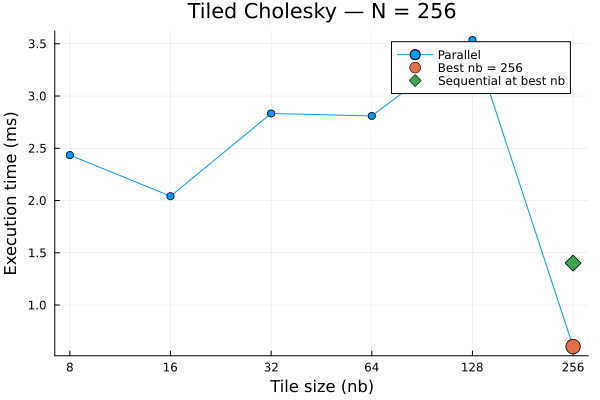

In [141]:
if HAS_PLOTS
    times_ms = [1000 * nb_times[nb] for nb in NBS]

    plt_t2 = plot(
        NBS, times_ms;
        marker = :circle,
        xlabel = "Tile size (nb)",
        ylabel = "Execution time (ms)",
        title = "Tiled Cholesky — N = $N",
        label = "Parallel",
        xscale = :log2,
        xticks = (NBS, string.(NBS))
    )

    scatter!(
        plt_t2,
        [BEST_NB], [1000 * t_par];
        label = "Best nb = $BEST_NB",
        markersize = 8
    )

    scatter!(
        plt_t2,
        [BEST_NB], [1000 * t_seq];
        label = "Sequential at best nb",
        markershape = :diamond,
        markersize = 8
    )

    display(plt_t2)
else
    println("Plots.jl is unavailable; timings are shown in the table above.")
end

#### From the plot we can notice the following:

- Best measured size: `nb = 256`, approximately `0.6 ms`
- Since \(nb=N\), this uses one tile and no parallel tasks
- Smaller tiles take longer, suggesting task overhead outweighs parallel benefits at \(N=256\)
- The curve is not `U-shaped`; the timing gap at nb = 256 does not demonstrate parallel speed-up

In [139]:
#Required exports

record!("T2_nb_times", nb_times)
record!("T2_best_nb", BEST_NB)
record!("T2_tasks_per_nb", tasks_per_nb);

In [142]:
# TODO · Task 2.3 — answers
# Explain the time-vs-nb curve: what limits performance at small nb, and what at large nb?
ANSWERS["T2_granularity"] = """
                                Small tiles incur scheduling overhead; large tiles reduce available parallelism.
                                For N = 256, nb = 256 was fastest (~0.6 ms), but spawned no tasks.
                                Confirm the choice with QUICK = false.
                            """   
# Where are the barriers in your tiled code? Which tile tasks could start earlier with a dependency (DAG) scheduler?
ANSWERS["T2_barriers"] = """
                            Two @sync barriers wait after TRSM and after UPDATE.
                            A DAG scheduler could start each update once its inputs are ready, and the next POTRF once its diagonal tile is fully updated.
                         """ 

"   Two @sync barriers wait after TRSM and after UPDATE.\n   A DAG scheduler could start each update once its inputs are ready, and the next POTRF once its diagonal tile is fully updated.\n"

In [143]:
# CHECK · Chapter 2
check("T2 tile_trsm! solves X·Lᵀ = B", () -> begin
    L = Matrix(LowerTriangular(rand(Xoshiro(1), 8, 8) + 8I)); B = rand(Xoshiro(2), 5, 8); X = copy(B)
    tile_trsm!(X, L); norm(X * L' - B) <= 1e-10 * norm(B)
end; points = 1)
check("T2 tile_update! lower triangle (informative)", () -> begin
    C = rand(Xoshiro(3), 6, 6); P = rand(Xoshiro(4), 6, 4); Q = rand(Xoshiro(5), 6, 4); C2 = copy(C)
    tile_update!(C2, P, Q); norm(tril(C2) - tril(C - P * Q')) <= 1e-12 * norm(C)
end)
check("T2 tiled, parallel, correct (n = 203, nb = 32)", () -> passes(B -> cholesky_tiled!(B, 32)); points = 2)
check("T2 tiled, sequential, correct", () -> passes(B -> cholesky_tiled!(B, 32; parallel = false)); points = 1)
check("T2 edge cases: ragged tiles (nb = 17) and nb > n (nb = 512)",
      () -> passes(B -> cholesky_tiled!(B, 17)) && passes(B -> cholesky_tiled!(B, 512)); points = 1)
check("T2 granularity sweep recorded", () -> haskey(RESULTS, "T2_nb_times") && length(RESULTS["T2_nb_times"]) >= 3 &&
                                             haskey(RESULTS, "T2_best_nb"); points = 1)

✅ T2 tile_trsm! solves X·Lᵀ = B  [1 pt]
✅ T2 tile_update! lower triangle (informative)
✅ T2 tiled, parallel, correct (n = 203, nb = 32)  [2 pt]
✅ T2 tiled, sequential, correct  [1 pt]
✅ T2 edge cases: ragged tiles (nb = 17) and nb > n (nb = 512)  [1 pt]
✅ T2 granularity sweep recorded  [1 pt]


true

> *Plot twist:* the director asks, "Do we really need 16 digits? The sensor data has 3." Half the bits means half the bytes to move and twice the SIMD lanes. Is that free speed?

---
# Chapter 3 · Precision — *Half the bits, twice the speed?* (14 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 3</b><br>Your kernels are generic in the element type <code>T</code>, so Float32 costs nothing to try. Float32 has ε ≈ 6·10⁻⁸ instead of 1·10⁻¹⁶, so you lose about eight digits. <b>Mixed-precision iterative refinement</b> keeps the speed and recovers the digits: do the O(n³) factorization in Float32, then correct the solution with cheap O(n²) residuals computed in Float64.</div>

### Task 3.1 · Same code, different precision
Time your best factorization in **Float64** and **Float32** on `generate_spd(N; T = …)`. For each, report time, GFlop/s, backward error and forward error.
*(Optional)* Try `Float16` at a small N. Why is it *slower* on most CPUs?
`record!("T3_times", Dict("Float64" => …, "Float32" => …))` and `record!("T3_backward_errors", Dict(…))`.

In [96]:
# TODO · Task 3.1
# A64 = generate_spd(N; T = Float64); A32 = generate_spd(N; T = Float32)
# t64 = bench(B -> cholesky_tiled!(B, BEST_NB), A64); t32 = …
# … backward / forward errors (use b and x_true converted to each precision) …
# record!("T3_times", Dict("Float64" => t64, "Float32" => t32)); record!("T3_backward_errors", Dict(…))

### Task 3.2 · Mixed-precision iterative refinement
```
F = factor!(Float32.(A))                          # O(n³) in fast low precision
x = Float64.(chol_solve!(F, Float32.(b)))
repeat:  r = b − A·x   (Float64)                  # O(n²)
         d = chol_solve!(F, Float32.(r))          # O(n²), reuses the factor
         x = x + d
until backward_error(A, x, b) ≤ tol  or  maxiter steps
```
Return `(x, iters, history)`, where `history` holds the backward error after each step. Set the default `factor!` to your fastest correct factorization.

In [97]:
# TODO · Task 3.2
"""
    solve_mixed_ir(A, b; maxiter = 10, tol = 4eps(Float64), factor! = cholesky_naive!) -> (x, iters, history)
Float32 factorization + Float64 iterative refinement. x is a Vector{Float64}.
"""
function solve_mixed_ir(A::AbstractMatrix{Float64}, b::AbstractVector{Float64};
                        maxiter::Int = 10, tol::Real = 4eps(Float64), factor! = cholesky_naive!)
    error("TODO: Task 3.2 — solve_mixed_ir")
end

solve_mixed_ir (generic function with 1 method)

### Task 3.3 · Experiment
Plot the backward-error history against the iteration number, with $\varepsilon_{64}$ and $\varepsilon_{32}$ as horizontal lines. Compare the **total** time of IR with a pure Float64 factorization plus solve.
`record!("T3_ir_iters", iters)`, `record!("T3_ir_time", …)`, `record!("T3_ir_backward_error", …)`.

In [98]:
# TODO · Task 3.3
# x_ir, it_ir, hist = solve_mixed_ir(A, b; factor! = B -> cholesky_tiled!(B, BEST_NB))
# t_ir = @elapsed solve_mixed_ir(A, b; factor! = …)
# record!("T3_ir_iters", it_ir); record!("T3_ir_time", t_ir); record!("T3_ir_backward_error", backward_error(A, x_ir, b))
ANSWERS["T3_tradeoff"] = ""   # Float32 vs Float64: measured speed-up, and how many digits were lost (backward vs forward error)?
ANSWERS["T3_ir"]       = ""   # Why does IR recover Float64 accuracy, and when would it fail to converge (hint: κ(A)·ε₃₂)?

""

In [99]:
# CHECK · Chapter 3
_own_impls() = [B -> cholesky_threads!(B; ntasks = 1), B -> cholesky_tiled!(B, 32), cholesky_left!]
check("T3 at least one of your own factorizations is accurate in Float32", () -> any(f -> try
        passes(f; T = Float32)
    catch
        false
    end, _own_impls()); points = 1)
_ir() = (A_ = generate_spd(203; seed = 11); b_ = A_ * generate_solution(203; seed = 12); (A_, b_, solve_mixed_ir(A_, b_)...))
check("T3 mixed-precision IR reaches Float64 accuracy (η ≤ 1e-14)", () -> begin
    A_, b_, x_, it_, h_ = _ir(); eltype(x_) == Float64 && backward_error(A_, x_, b_) <= 1e-14
end; points = 3)
check("T3 IR converges within 10 refinement steps", () -> begin
    A_, b_, x_, it_, h_ = _ir(); it_ <= 10 && length(h_) >= 1
end; points = 1)
check("T3 precision timings recorded", () -> haskey(RESULTS, "T3_times") && haskey(RESULTS["T3_times"], "Float32") &&
                                             haskey(RESULTS["T3_times"], "Float64"); points = 1)

✅ T3 at least one of your own factorizations is accurate in Float32  [1 pt]
   ↳ TODO: Task 3.2 — solve_mixed_ir
❌ T3 mixed-precision IR reaches Float64 accuracy (η ≤ 1e-14)  [3 pt]
   ↳ TODO: Task 3.2 — solve_mixed_ir
❌ T3 IR converges within 10 refinement steps  [1 pt]
❌ T3 precision timings recorded  [1 pt]


false

> *Plot twist:* Float32 was faster, but not by as much as the halved byte count suggests, and the single-thread baseline is still painfully slow. A profiler shows the CPU **waiting for memory**, not computing. Time to look at how data moves.

---
# Chapter 4 · Reducing data movement — *The road, not the engine* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 4</b><br>Julia stores matrices <b>column by column</b>. The baseline's inner loop <code>A[i,k]·A[j,k]</code> walks <i>along rows</i>, so every access jumps n·8 bytes and lands on a new cache line: the core spends its time waiting for memory. Reorder the loops so the innermost one runs <b>down a column</b>, remove bounds checks, let the compiler vectorize, and make sure not a single byte is allocated on the heap.</div>

### Task 4.1 · Implement `cholesky_left!(A)`: left-looking, column-oriented ("jki")
For $j = 1{:}n$:  for $k = 1{:}j{-}1$: $A_{ij} \mathrel{-}= A_{ik}A_{jk}$ for $i = j{:}n$, with the **innermost loop over $i$** (stride 1). Then $A_{jj} \leftarrow \sqrt{A_{jj}}$ and $A_{j+1:n,\,j} \mathrel{/}= A_{jj}$.
Requirements: `@inbounds` and `@simd` on the inner loop, and **zero heap allocations**. Slices like `A[j:n, k]` copy, so use loops or `view`s.

In [100]:
# TODO · Task 4.1
"""
    cholesky_left!(A) -> A
Left-looking, cache-friendly, allocation-free sequential Cholesky (L in the lower triangle).
"""
function cholesky_left!(A::AbstractMatrix{T}) where {T<:AbstractFloat}
    error("TODO: Task 4.1 — cholesky_left!")
end

cholesky_left! (generic function with 1 method)

### Task 4.2 · Experiment: measure the effect of data movement
1. Time `cholesky_naive!` and `cholesky_left!` (both sequential) at $N$ (or `NAIVE_MAX_N`). Measure `allocations(f!, A)` for every implementation so far.
2. Build a **traffic model**: estimate the bytes moved by the naive inner loop when nothing stays in cache, and divide by the measured time. How close is that to the machine bandwidth? You will measure the bandwidth in Chapter 7.
3. Apply the same ideas (`@inbounds`, `@simd`, column-order loops, views) to your Chapter 1 and Chapter 2 kernels and re-time them. Which tile size makes three tiles fit in your L2 cache ($3\,nb^2 \cdot 8$ bytes)? Compare it with `BEST_NB`.
4. `record!("T4_times", Dict("naive" => …, "left" => …, …))` and `record!("T4_allocations", Dict(name => bytes))`.

In [101]:
# TODO · Task 4.2
nmax = min(N, NAIVE_MAX_N); Am = generate_spd(nmax)
# t_naive = bench(cholesky_naive!, Am); t_left = bench(cholesky_left!, Am)
# allocs = Dict("naive" => allocations(cholesky_naive!, Am), "left" => allocations(cholesky_left!, Am), …)
# record!("T4_times", Dict("naive" => t_naive, "left" => t_left)); record!("T4_allocations", allocs)
ANSWERS["T4_traffic"] = ""   # your traffic model for naive vs left-looking, and the effective bandwidth it implies
ANSWERS["T4_cache"]   = ""   # which nb fits 3 tiles in L2 on your CPU, how does it compare with BEST_NB, and why?

""

In [102]:
# CHECK · Chapter 4
check("T4 cholesky_left! correct", () -> passes(cholesky_left!) && passes(cholesky_left!; T = Float32); points = 2)
check("T4 cholesky_left! allocation-free (≤ 256 bytes)", () -> allocations(cholesky_left!, generate_spd(128)) <= 256; points = 2)
check("T4 left-looking faster than the baseline", () -> RESULTS["T4_times"]["left"] < RESULTS["T4_times"]["naive"]; points = 1)
check("T4 times and allocations recorded", () -> haskey(RESULTS, "T4_times") && haskey(RESULTS, "T4_allocations"); points = 1)

   ↳ TODO: Task 4.1 — cholesky_left!
❌ T4 cholesky_left! correct  [2 pt]
   ↳ 

TODO: Task 4.1 — cholesky_left!
❌ T4 cholesky_left! allocation-free (≤ 256 bytes)  [2 pt]
   ↳ KeyError: key "T4_times" not found
❌ T4 left-looking faster than the baseline  [1 pt]
❌ T4 times and allocations recorded  [1 pt]


false

> *Plot twist:* a colleague drops a hint in the chat: *"Vendors have spent decades tuning exactly this. Have you compared with LAPACK?"*

---
# Chapter 5 · Vendor-optimized libraries — *Standing on the shoulders of giants* (10 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 5</b><br>Julia ships with OpenBLAS (and can use Intel MKL through <code>MKL.jl</code>). LAPACK's <code>potrf</code> is a blocked Cholesky built on BLAS-3 kernels that are tuned per CPU, with register blocking, packing and AVX-512 where the hardware has it. Measure the gap first, then try to <b>combine</b> approaches: keep your tile scheduler and plug vendor kernels into the tiles.</div>

### Task 5.1 · Implement
* `cholesky_lapack!(A)`: call `LAPACK.potrf!('L', A)`, which returns `(A, info)`, and throw `PosDefException(info)` if `info > 0`.
* `cholesky_tiled_blas!(A, nb; parallel)`: your Chapter-2 algorithm with
  POTRF → `LAPACK.potrf!('L', Akk)` · TRSM → `BLAS.trsm!('R', 'L', 'T', 'N', one(T), Lkk, Aik)` ·
  SYRK → `BLAS.syrk!('L', 'N', -one(T), Aik, one(T), Aii)` · GEMM → `BLAS.gemm!('N', 'T', -one(T), Aik, Ajk, one(T), Aij)`.
  Julia tasks combined with multi-threaded BLAS **oversubscribe** the cores. Call `BLAS.set_num_threads(1)` around the parallel part and **restore** `BLAS_THREADS0` afterwards, inside `try … finally`.

In [103]:
# TODO · Task 5.1
"cholesky_lapack!(A) -> A : LAPACK potrf on the lower triangle."
function cholesky_lapack!(A::AbstractMatrix{T}) where {T<:AbstractFloat}
    error("TODO: Task 5.1 — cholesky_lapack!")
end

"cholesky_tiled_blas!(A, nb; parallel = true) -> A : tiled Cholesky with BLAS/LAPACK tile kernels."
function cholesky_tiled_blas!(A::AbstractMatrix{T}, nb::Int; parallel::Bool = true) where {T<:AbstractFloat}
    error("TODO: Task 5.1 — cholesky_tiled_blas!")
end

cholesky_tiled_blas! (generic function with 1 method)

### Task 5.2 · Experiment: how far behind are we?
At size $N$ (Float64), time: your best Chapter 1, 2 and 4 versions, `cholesky_tiled_blas!` (sweep nb, which is usually larger than `BEST_NB`), `cholesky_lapack!` with **1** BLAS thread and with **all** BLAS threads, and `LinearAlgebra.cholesky(Symmetric(A))`.
Report each as a percentage of LAPACK's GFlop/s. *(Optional)* Repeat with `using MKL` if your CPU is Intel.
`record!("T5_times", Dict(name => t))`.

In [104]:
# TODO · Task 5.2
# BLAS.set_num_threads(1);              t_lapack1   = bench(cholesky_lapack!, A)
# BLAS.set_num_threads(BLAS_THREADS0);  t_lapackall = bench(cholesky_lapack!, A)
# … tiled_blas nb sweep, comparison table in % of LAPACK …
# record!("T5_times", Dict("lapack_1thread" => t_lapack1, "lapack_all" => t_lapackall, …))
BEST_NB_BLAS = 256                # ← set from your sweep (used in Chapter 6)
ANSWERS["T5_oversubscription"] = ""   # what happened with Julia tasks × BLAS threads, and how did you avoid it?
ANSWERS["T5_gap"]              = ""   # why is the vendor library faster than your loops (be specific: blocking, packing, SIMD width, FMA)?

""

In [105]:
# CHECK · Chapter 5
check("T5 cholesky_lapack! correct", () -> passes(cholesky_lapack!) && passes(cholesky_lapack!; T = Float32); points = 1)
check("T5 cholesky_lapack! throws PosDefException on an indefinite matrix", () -> try
        cholesky_lapack!([1.0 2.0; 2.0 1.0]); false
    catch e
        e isa PosDefException
    end; points = 1)
check("T5 cholesky_tiled_blas! correct (n = 203, nb = 32 and nb = 512)",
      () -> passes(B -> cholesky_tiled_blas!(B, 32)) && passes(B -> cholesky_tiled_blas!(B, 512)); points = 2)
check("T5 BLAS thread count restored", () -> BLAS.get_num_threads() == BLAS_THREADS0; points = 1)
check("T5 comparison recorded (≥ 4 variants)", () -> haskey(RESULTS, "T5_times") && length(RESULTS["T5_times"]) >= 4; points = 1)

   ↳ TODO: Task 5.1 — cholesky_lapack!
❌ T5 cholesky_lapack! correct  [1 pt]
❌ T5 cholesky_lapack! throws PosDefException on an indefinite matrix  [1 pt]
   ↳ TODO: Task 5.1 — cholesky_tiled_blas!
❌ T5 cholesky_tiled_blas! correct (n = 203, nb = 32 and nb = 512)  [2 pt]
✅ T5 BLAS thread count restored  [1 pt]
❌ T5 comparison recorded (≥ 4 variants)  [1 pt]


false

> *Plot twist:* the director wants **one chart** for the board meeting: "Which version, at which size, and how fast?" A single timing at one N is an anecdote, not a benchmark.

---
# Chapter 6 · Benchmarking — *The scoreboard* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 6</b><br>A fair benchmark warms up the JIT, repeats each run and keeps the <b>minimum</b>, fixes the thread counts, validates every result, and sweeps the size. Small matrices fit in cache and large ones do not, so performance depends on N. Report both <b>Time</b> and the <b>rate of execution in GFlop/s</b> (n³/3 flops ÷ time), in both precisions.</div>

### Task 6.1 · The sweep
For every implementation in `IMPLS`, every size in `SIZES` (the baseline only up to `NAIVE_MAX_N`) and both `Float64` and `Float32`, push one `measure(...)` row into `BENCH`. Do not change the schema; the grader reads it. Add your own variants to `IMPLS` if you like.

In [106]:
# TODO · Task 6.1
IMPLS = [                               # name => in-place factorization returning the matrix
    "naive"      => cholesky_naive!,
    "threads"    => B -> cholesky_threads!(B),
    "left"       => cholesky_left!,
    "tiled"      => B -> cholesky_tiled!(B, BEST_NB),
    "tiled_blas" => B -> cholesky_tiled_blas!(B, BEST_NB_BLAS),
    "lapack"     => cholesky_lapack!,
]
empty!(BENCH)
# for T in (Float64, Float32), n in SIZES, (name, f!) in IMPLS
#     name == "naive" && n > NAIVE_MAX_N && continue
#     A_ = generate_spd(n; T = T); b_ = A_ * generate_solution(n; T = T)
#     safe_measure!(BENCH, name, f!, A_, b_)          # skips (with a warning) anything unfinished
# end
show_table(BENCH)

(no rows)


### Task 6.2 · Plots and scaling exponent
1. Two log-log plots per precision: **Time vs N**, with an $N^3$ reference line, and **GFlop/s vs N**.
2. Fit the empirical exponent $t \propto N^{s}$ on the largest sizes with `loglog_slope`, and `record!("T6_slope", Dict(impl => s))` for the Float64 rows.
3. `record!("T6_best", name)`: the fastest implementation at the largest N in Float64.

In [107]:
# TODO · Task 6.2
loglog_slope(ns, ts) = ([ones(length(ns)) log.(ns)] \ log.(ts))[2]      # PROVIDED: least-squares slope of log t vs log N
# rows64 = filter(r -> r.precision == "Float64", BENCH)
# slopes = Dict(name => loglog_slope([r.N for r in rows if r.impl == name], [r.time_s for r in rows if r.impl == name]) for name in …)
# if HAS_PLOTS … plot(…; xscale = :log10, yscale = :log10) … end
# record!("T6_slope", slopes); record!("T6_best", …)
ANSWERS["T6_methodology"] = ""   # how did you make the measurements fair and repeatable (warm-up, min of reps, threads, other load)?
ANSWERS["T6_observations"] = ""  # where do the curves cross, where does GFlop/s plateau or drop, and why (cache sizes, parallel overhead)?

""

In [108]:
# CHECK · Chapter 6
_BENCH_KEYS = (:impl, :precision, :N, :time_s, :gflops, :backward_error)
_EPS = Dict("Float64" => eps(Float64), "Float32" => eps(Float32), "Float16" => eps(Float16))
check("T6 BENCH rows follow the schema", () -> !isempty(BENCH) && all(r -> all(haskey(r, k) for k in _BENCH_KEYS), BENCH); points = 2)
check("T6 coverage: ≥ 4 implementations × ≥ 3 sizes × Float64 & Float32",
      () -> length(unique(r.impl for r in BENCH)) >= 4 && length(unique(r.N for r in BENCH)) >= 3 &&
            issubset(["Float64", "Float32"], unique(r.precision for r in BENCH)); points = 2)
check("T6 every benchmarked run passes the backward-error test",
      () -> all(r -> r.backward_error <= 10 * r.N * get(_EPS, r.precision, eps(Float16)), BENCH); points = 1)
# small QUICK sizes are dominated by overheads, so the exponent is only range-checked in a full run
check("T6 scaling exponents recorded" * (QUICK ? "" : " and plausible (1.5 ≤ s ≤ 4)"),
      () -> haskey(RESULTS, "T6_slope") && !isempty(RESULTS["T6_slope"]) &&
            all(s -> isfinite(s) && (QUICK || 1.5 <= s <= 4.0), values(RESULTS["T6_slope"])); points = 1)

❌ T6 BENCH rows follow the schema  [2 pt]
❌ T6 coverage: ≥ 4 implementations × ≥ 3 sizes × Float64 & Float32  [2 pt]
✅ T6 every benchmarked run passes the backward-error test  [1 pt]
❌ T6 scaling exponents recorded  [1 pt]


false

> *Plot twist:* LAPACK reaches some number X of GFlop/s. Is that good? Without knowing what the machine *could* do, X means nothing.

---
# Chapter 7 · The roofline model — *How far from the ceiling?* (14 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 7</b><br>The roofline model says that a kernel with <b>arithmetic intensity</b> I (flop per byte moved from memory) can reach at most <b>min(P<sub>peak</sub>, I × B<sub>mem</sub>)</b>. Measure the two ceilings of your machine, estimate I for each implementation, and place your measured points on the chart. Each point is then either <i>memory-bound</i> or <i>compute-bound</i>, and the gap to its roof tells you how much there is still to gain.</div>

In [109]:
# PROVIDED · roofline model and plot
roofline(ai, peak, bw) = min(peak, ai * bw)      # attainable GFlop/s at intensity ai (flop/byte), bw in GB/s

"plot_roofline(peak, bw, Dict(name => (ai, achieved_gflops))) — prints a table, and plots if Plots.jl is available."
function plot_roofline(peak, bw, points::AbstractDict)
    ridge = peak / bw
    @printf("peak = %.1f GFlop/s | bandwidth = %.1f GB/s | ridge point = %.2f flop/byte\n", peak, bw, ridge)
    for (name, (ai, g)) in points
        roof = roofline(ai, peak, bw)
        @printf("  %-12s AI = %8.3f  achieved = %8.2f  roof = %8.2f GFlop/s  (%5.1f%% of roof, %s-bound)\n",
                name, ai, g, roof, 100 * g / roof, ai < ridge ? "memory" : "compute")
    end
    HAS_PLOTS || return nothing
    ais = 10.0 .^ range(-3, 3; length = 300)
    p = plot(ais, roofline.(ais, peak, bw); xscale = :log10, yscale = :log10, lw = 3, color = :black, label = "roofline",
             xlabel = "arithmetic intensity (flop/byte)", ylabel = "GFlop/s", title = "Roofline — Cholesky implementations",
             legend = :bottomright)
    vline!(p, [ridge]; ls = :dash, color = :gray, label = "ridge point")
    for (name, (ai, g)) in points
        scatter!(p, [ai], [g]; ms = 7, label = name)
    end
    return p
end

plot_roofline (generic function with 1 method)

### Task 7.1 · The two ceilings
* **Memory bandwidth:** implement the STREAM triad $a_i = b_i + s\,c_i$ on Float64 vectors much larger than the last-level cache, parallelized with `Threads.@threads`. Count $3 \cdot 8n$ bytes per sweep and return the best rate in GB/s.
* **Peak compute:** measured as the GFlop/s of a large `BLAS.gemm!` ($2n^3$ flops) with all BLAS threads; theoretical from the CPU spec sheet as cores × GHz × SIMD lanes × 2 (FMA) × FMA units.

In [110]:
# TODO · Task 7.1
"stream_triad_bw(; n, reps = 5) -> GB/s (best of reps), threaded STREAM triad (3 vectors of n Float64)."
function stream_triad_bw(; n::Int = QUICK ? 2^22 : 2^24, reps::Int = 5)
    error("TODO: Task 7.1 — stream_triad_bw")
end
PEAK_BW            = NaN    # ← stream_triad_bw()
PEAK_GFLOPS        = NaN    # ← measured with a large BLAS.gemm!
PEAK_GFLOPS_THEORY = NaN    # ← from the spec sheet (write the formula you used in ANSWERS["T7_ai_derivation"])

NaN

### Task 7.2 · Arithmetic intensity and the roofline chart
1. Estimate the arithmetic intensity (flop per byte from **memory**, for Float64) of each implementation. For example: the naive inner loop does 2 flops per two loaded Float64 values (16 B) if nothing stays in cache; a GEMM on $nb \times nb$ tiles does $2nb^3$ flops on $3nb^2 \cdot 8$ B.
2. Use `plot_roofline(PEAK_GFLOPS, PEAK_BW, Dict(name => (ARITH_INTENSITY[name], achieved GFlop/s at your largest N from BENCH)))`.
3. Fill `BOUND[name] = "memory"` or `"compute"` according to the model, meaning which side of the ridge point it sits on.
4. `record!("T7_fraction_of_roof", Dict(name => achieved / roof))`.

In [111]:
# TODO · Task 7.2
ARITH_INTENSITY = Dict{String,Float64}(
    # "naive"      => …,
    # "left"       => …,
    # "tiled"      => …,
    # "tiled_blas" => …,
    # "lapack"     => …,
)
BOUND = Dict{String,String}()        # name => "memory" | "compute"
# plot_roofline(PEAK_GFLOPS, PEAK_BW, Dict(name => (ARITH_INTENSITY[name], …) for name in keys(ARITH_INTENSITY)))
# record!("T7_fraction_of_roof", …)
ANSWERS["T7_ai_derivation"]  = ""   # how you derived each intensity and the theoretical peak
ANSWERS["T7_interpretation"] = ""   # which implementations are memory- vs compute-bound, how far each is from its roof, what would move it up

""

In [112]:
# CHECK · Chapter 7
check("T7 memory bandwidth measured and plausible (1–3000 GB/s)", () -> isfinite(PEAK_BW) && 1 <= PEAK_BW <= 3000; points = 1)
check("T7 peak GFlop/s measured and plausible", () -> isfinite(PEAK_GFLOPS) && 1 <= PEAK_GFLOPS <= 1e5 && isfinite(PEAK_GFLOPS_THEORY); points = 1)
check("T7 arithmetic intensity for ≥ 4 implementations", () -> length(ARITH_INTENSITY) >= 4 && all(v -> 0 < v < 1e4, values(ARITH_INTENSITY)); points = 1)
check("T7 bounds consistent with the ridge point",
      () -> length(BOUND) >= 4 && all(k -> BOUND[k] == (ARITH_INTENSITY[k] * PEAK_BW < PEAK_GFLOPS ? "memory" : "compute"), keys(BOUND)); points = 2)

❌ T7 memory bandwidth measured and plausible (1–3000 GB/s)  [1 pt]
❌ T7 peak GFlop/s measured and plausible  [1 pt]
❌ T7 arithmetic intensity for ≥ 4 implementations  [1 pt]
❌ T7 bounds consistent with the ridge point  [2 pt]


false

> *Plot twist:* the numbers are in, the chart is drawn, and the director's meeting is on Friday.

---
# Chapter 8 · Report card & conclusions — *Briefing the director* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 8</b><br>Friday afternoon. The director has five minutes and one question: <i>"Which solver do we deploy, how fast is it, and can we trust it?"</i> Answer on one page, with numbers.</div>

### Performance report card
| Item | Your answer |
|---|---|
| Hardware: CPU, cores, Julia threads, BLAS library and threads | |
| Baseline (Chapter 0) at N = …: time, GFlop/s | |
| Best parallel version you wrote (Chapters 1/2/4): time, GFlop/s, speed-up over baseline, parallel efficiency | |
| Best granularity (nb) and why | |
| Float32 speed-up · digits lost · mixed-IR result | |
| Effect of data-movement optimizations (time, allocations) | |
| Vendor library: GFlop/s, % of measured peak · your best code as % of LAPACK | |
| Benchmark: fastest implementation per size range (Time & GFlop/s) | |
| Roofline: memory- vs compute-bound implementations, % of roof | |
| Accuracy: backward error of the recommended solver, digits lost in Float32 and recovered by mixed IR | |
| **Recommendation** for N ≈ 4000, hourly operation | |
| **Key conclusions** (3–5 bullets: what worked, what did not, next steps) | |

In [113]:
# TODO · Task 8
ANSWERS["T8_recommendation"] = ""   # which implementation and precision you would deploy for N ≈ 4000, and why (speed, accuracy, maintainability)
ANSWERS["T8_conclusions"]    = ""   # 3–5 bullets: what worked, what did not, what you would do next

""

In [114]:
# CHECK · Chapter 8
check("T8 every ANSWERS entry filled (≥ 20 characters)", () -> length(ANSWERS) >= 16 && all(v -> length(strip(v)) >= 20, values(ANSWERS)); points = 1)

❌ T8 every ANSWERS entry filled (≥ 20 characters)  [1 pt]


false

## ★ HPC bonus (+10 pts)
* **A · Task-DAG scheduling:** remove the phase barriers in Chapter 2. Each tile task waits only on the tasks it depends on (spawn tasks that `fetch` their predecessors, or use `Dagger.jl`). Compare with the fork-join version.
* **B · GPU:** `CUDA.jl` / `AMDGPU.jl` / `Metal.jl` — `cholesky` on the device, in Float64 and Float32, including transfer time. At which N does the GPU win?
* **C · Recursive Cholesky:** cache-oblivious recursive splitting into two halves (POTRF, TRSM, SYRK, POTRF). Compare with tiled and LAPACK.
* **D · Distributed memory:** `Distributed.jl` or `MPI.jl` with a 1-D block-cyclic column distribution. Measure strong scaling over processes.

Record your bonus results with `record!("BONUS_…", …)` and describe them in `ANSWERS["BONUS"]`.

In [115]:
# TODO · Bonus (optional)

---
## Export for grading
Run last, after **Kernel → Restart & Run All**. Writes `results_team<ID>.json` (results, answers, checks, benchmark rows, roofline values, environment) and `bench_team<ID>.csv`. Submit them together with the executed notebook.

In [116]:
# PROVIDED · export everything the grader needs
_get(s::Symbol) = isdefined(Main, s) ? getfield(Main, s) : nothing
env = Dict("julia" => string(VERSION), "threads" => nthreads(), "blas_threads" => BLAS.get_num_threads(),
           "blas" => string(BLAS.get_config()), "cpu" => Sys.cpu_info()[1].model, "cpu_threads" => Sys.CPU_THREADS,
           "quick" => QUICK, "N" => N, "sizes" => SIZES, "timestamp" => string(now()))
roof = Dict("peak_gflops" => _get(:PEAK_GFLOPS), "peak_gflops_theory" => _get(:PEAK_GFLOPS_THEORY),
            "bandwidth_GBs" => _get(:PEAK_BW), "arith_intensity" => _get(:ARITH_INTENSITY), "bound" => _get(:BOUND))
out = Dict("team_id" => TEAM_ID, "env" => env, "results" => RESULTS, "answers" => ANSWERS, "checks" => CHECKS,
           "bench" => BENCH, "roofline" => roof,
           "best_nb" => _get(:BEST_NB), "best_nb_blas" => _get(:BEST_NB_BLAS))
fname = "results_team$(TEAM_ID).json"
open(io -> write(io, to_json(out)), fname, "w")
try
    open("bench_team$(TEAM_ID).csv", "w") do io
        println(io, "impl,precision,N,threads,time_s,gflops,backward_error")
        for r in BENCH
            println(io, join((r.impl, r.precision, r.N, r.threads, r.time_s, r.gflops, r.backward_error), ","))
        end
    end
catch err
    @warn "could not write the benchmark CSV" err
end
npass = count(v -> v["pass"], values(CHECKS))
auto  = sum((v["points"] for v in values(CHECKS) if v["pass"]); init = 0)
total = sum((v["points"] for v in values(CHECKS)); init = 0)
@printf("wrote %s | checks passed: %d / %d | automatic points: %g / %g (the other 58 points are read by the instructor)\n",
        fname, npass, length(CHECKS), auto, total)

wrote results_team1013.json | checks passed: 13 / 37 | automatic points: 8 / 42 (the other 58 points are read by the instructor)


<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Hatem Ltaief</div>